In [29]:
import pandas as pd
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

In [30]:

# Load the cleaned dataset
df = pd.read_csv("election_cleaned.csv")


In [31]:
df.head()

,username,text,likeCount,quoteCount,date,processed_text,Tokens,Filtered_Tokens,Lemmatized_Tokens,POS_Tags,cleaned_tweet
0,SATraveler2,@MdBreathe continued- \nto develop a techniqu...,0.0,0.0,2024-11-20 23:59:59,continue develop technique hide evidence human...,"['continue', 'develop', 'technique', 'hide', '...","['continue', 'develop', 'technique', 'hide', '...","['continue', 'develop', 'technique', 'hide', '...","[('continue', 'VERB'), (' \n ', 'SPACE'), ('de...",continued to develop a technique for hiding ev...
1,JoeZumwalt,@UROCKlive1 all these banderite/nazi sycophant...,0.0,0.0,2024-11-20 23:59:57,banderitenazi sycophant dnc,"['banderitenazi', 'sycophant', 'dnc']","['banderitenazi', 'sycophant', 'dnc']","['banderitenazi', 'sycophant', 'dnc']","[('banderitenazi', 'PROPN'), ('sycophant', 'PR...",all these banderitenazi sycophants to the dnc
2,67sharona,Laken Rileys Death Would Of Never Ever Happene...,1.0,0.0,2024-11-20 23:59:56,laken rileys death happen president justicefor...,"['laken', 'rileys', 'death', 'happen', 'presid...","['laken', 'rileys', 'death', 'happen', 'presid...","['laken', 'rileys', 'death', 'happen', 'presid...","[('laken', 'VERB'), ('rileys', 'PROPN'), ('dea...",laken rileys death would of never ever happene...
3,TruthAboutF,POV: you go downstairs in the middle of the ni...,14.0,0.0,2024-11-20 23:59:55,pov downstairs middle night bowl froot loop ft...,"['pov', 'downstairs', 'middle', 'night', 'bowl...","['pov', 'downstairs', 'middle', 'night', 'bowl...","['pov', 'downstairs', 'middle', 'night', 'bowl...","[('pov', 'PROPN'), ('downstairs', 'ADV'), ('mi...",pov you go downstairs in the middle of the nig...
4,Hump98Clint,"@mtgreenee This is a good question, are you no...",1.0,0.0,2024-11-20 23:59:53,good question member republican party list people,"['good', 'question', 'member', 'republican', '...","['good', 'question', 'member', 'republican', '...","['good', 'question', 'member', 'republican', '...","[('good', 'ADJ'), ('question', 'NOUN'), ('memb...",this is a good question are you not a member o...


# Calculation of Sentiment score

In [32]:
# Initialize the Sentiment Analyzer
analyzer = SentimentIntensityAnalyzer()

In [33]:
# Function to get sentiment scores
def get_sentiment(text):
    sentiment_scores = analyzer.polarity_scores(str(text))  # Get sentiment scores
    compound_score = sentiment_scores['compound']  # Overall sentiment score
    return compound_score

In [34]:
# Apply VADER sentiment analysis
df["sentiment_score"] = df["cleaned_tweet"].apply(get_sentiment)


In [35]:
#  Function to classify sentiment
def classify_sentiment(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

df["sentiment_label"] = df["sentiment_score"].apply(classify_sentiment)


In [36]:
df.head()

,username,text,likeCount,quoteCount,date,processed_text,Tokens,Filtered_Tokens,Lemmatized_Tokens,POS_Tags,cleaned_tweet,sentiment_score,sentiment_label
0,SATraveler2,@MdBreathe continued- \nto develop a techniqu...,0.0,0.0,2024-11-20 23:59:59,continue develop technique hide evidence human...,"['continue', 'develop', 'technique', 'hide', '...","['continue', 'develop', 'technique', 'hide', '...","['continue', 'develop', 'technique', 'hide', '...","[('continue', 'VERB'), (' \n ', 'SPACE'), ('de...",continued to develop a technique for hiding ev...,0.4019,Positive
1,JoeZumwalt,@UROCKlive1 all these banderite/nazi sycophant...,0.0,0.0,2024-11-20 23:59:57,banderitenazi sycophant dnc,"['banderitenazi', 'sycophant', 'dnc']","['banderitenazi', 'sycophant', 'dnc']","['banderitenazi', 'sycophant', 'dnc']","[('banderitenazi', 'PROPN'), ('sycophant', 'PR...",all these banderitenazi sycophants to the dnc,0.0000,Neutral
2,67sharona,Laken Rileys Death Would Of Never Ever Happene...,1.0,0.0,2024-11-20 23:59:56,laken rileys death happen president justicefor...,"['laken', 'rileys', 'death', 'happen', 'presid...","['laken', 'rileys', 'death', 'happen', 'presid...","['laken', 'rileys', 'death', 'happen', 'presid...","[('laken', 'VERB'), ('rileys', 'PROPN'), ('dea...",laken rileys death would of never ever happene...,-0.5994,Negative
3,TruthAboutF,POV: you go downstairs in the middle of the ni...,14.0,0.0,2024-11-20 23:59:55,pov downstairs middle night bowl froot loop ft...,"['pov', 'downstairs', 'middle', 'night', 'bowl...","['pov', 'downstairs', 'middle', 'night', 'bowl...","['pov', 'downstairs', 'middle', 'night', 'bowl...","[('pov', 'PROPN'), ('downstairs', 'ADV'), ('mi...",pov you go downstairs in the middle of the nig...,0.0000,Neutral
4,Hump98Clint,"@mtgreenee This is a good question, are you no...",1.0,0.0,2024-11-20 23:59:53,good question member republican party list people,"['good', 'question', 'member', 'republican', '...","['good', 'question', 'member', 'republican', '...","['good', 'question', 'member', 'republican', '...","[('good', 'ADJ'), ('question', 'NOUN'), ('memb...",this is a good question are you not a member o...,0.6808,Positive


In [13]:
# Save the dataset with sentiment analysis results
df.to_csv("election_sentiment.csv", index=False)

print(" Sentiment analysis completed! Results saved in 'election_sentiment.csv'.")


 Sentiment analysis completed! Results saved in 'election_sentiment.csv'.


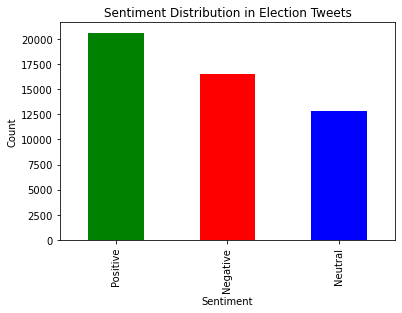

In [37]:
import matplotlib.pyplot as plt

# Count each sentiment label
df["sentiment_label"] = df["sentiment_score"].apply(lambda x: "Positive" if x > 0.05 else "Negative" if x < -0.05 else "Neutral")

# Plot sentiment distribution
df["sentiment_label"].value_counts().plot(kind="bar", color=["green", "red", "blue"])
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.title("Sentiment Distribution in Election Tweets")
plt.show()


# Textblob for comparison

In [38]:
from textblob import TextBlob



In [39]:

def textblob_sentiment(text):
    score = TextBlob(str(text)).sentiment.polarity
    return "Positive" if score > 0 else "Negative" if score < 0 else "Neutral"

df["textblob_label"] = df["cleaned_tweet"].apply(textblob_sentiment)




In [40]:
# Compare VADER and TextBlob results
comparison = df[["sentiment_label", "textblob_label"]].value_counts()
print(comparison)

sentiment_label  textblob_label
Positive         Positive          12286
Neutral          Neutral            9878
Negative         Negative           7466
Positive         Neutral            5326
Negative         Positive           4551
                 Neutral            4502
Positive         Negative           2992
Neutral          Positive           2023
                 Negative            976
Name: count, dtype: int64


In [41]:
total_cases = 12286 + 9878 + 7466 + 5326 + 4551 + 4502 + 2992 + 2023 + 976
agreement_cases = 12286 + 9878 + 7466
agreement_rate = agreement_cases / total_cases
print(f"Agreement Rate: {agreement_rate:.2%}")


Agreement Rate: 59.26%


<AxesSubplot:xlabel='sentiment_label'>

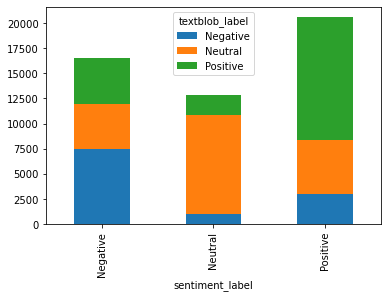

In [42]:
df.groupby(["sentiment_label", "textblob_label"]).size().unstack().plot(kind="bar", stacked=True)


In [43]:
from sklearn.metrics import classification_report
print(classification_report(df["sentiment_label"], df["textblob_label"]))


              precision    recall  f1-score   support

    Negative       0.65      0.45      0.53     16519
     Neutral       0.50      0.77      0.61     12877
    Positive       0.65      0.60      0.62     20604

    accuracy                           0.59     50000
   macro avg       0.60      0.61      0.59     50000
weighted avg       0.61      0.59      0.59     50000



In [44]:
print(df.columns)  # Lists all available column names


Index(['username', 'text', 'likeCount', 'quoteCount', 'date', 'processed_text',
       'Tokens', 'Filtered_Tokens', 'Lemmatized_Tokens', 'POS_Tags',
       'cleaned_tweet', 'sentiment_score', 'sentiment_label',
       'textblob_label'],
      dtype='object')


In [45]:
df.head()

,username,text,likeCount,quoteCount,date,processed_text,Tokens,Filtered_Tokens,Lemmatized_Tokens,POS_Tags,cleaned_tweet,sentiment_score,sentiment_label,textblob_label
0,SATraveler2,@MdBreathe continued- \nto develop a techniqu...,0.0,0.0,2024-11-20 23:59:59,continue develop technique hide evidence human...,"['continue', 'develop', 'technique', 'hide', '...","['continue', 'develop', 'technique', 'hide', '...","['continue', 'develop', 'technique', 'hide', '...","[('continue', 'VERB'), (' \n ', 'SPACE'), ('de...",continued to develop a technique for hiding ev...,0.4019,Positive,Positive
1,JoeZumwalt,@UROCKlive1 all these banderite/nazi sycophant...,0.0,0.0,2024-11-20 23:59:57,banderitenazi sycophant dnc,"['banderitenazi', 'sycophant', 'dnc']","['banderitenazi', 'sycophant', 'dnc']","['banderitenazi', 'sycophant', 'dnc']","[('banderitenazi', 'PROPN'), ('sycophant', 'PR...",all these banderitenazi sycophants to the dnc,0.0000,Neutral,Neutral
2,67sharona,Laken Rileys Death Would Of Never Ever Happene...,1.0,0.0,2024-11-20 23:59:56,laken rileys death happen president justicefor...,"['laken', 'rileys', 'death', 'happen', 'presid...","['laken', 'rileys', 'death', 'happen', 'presid...","['laken', 'rileys', 'death', 'happen', 'presid...","[('laken', 'VERB'), ('rileys', 'PROPN'), ('dea...",laken rileys death would of never ever happene...,-0.5994,Negative,Neutral
3,TruthAboutF,POV: you go downstairs in the middle of the ni...,14.0,0.0,2024-11-20 23:59:55,pov downstairs middle night bowl froot loop ft...,"['pov', 'downstairs', 'middle', 'night', 'bowl...","['pov', 'downstairs', 'middle', 'night', 'bowl...","['pov', 'downstairs', 'middle', 'night', 'bowl...","[('pov', 'PROPN'), ('downstairs', 'ADV'), ('mi...",pov you go downstairs in the middle of the nig...,0.0000,Neutral,Neutral
4,Hump98Clint,"@mtgreenee This is a good question, are you no...",1.0,0.0,2024-11-20 23:59:53,good question member republican party list people,"['good', 'question', 'member', 'republican', '...","['good', 'question', 'member', 'republican', '...","['good', 'question', 'member', 'republican', '...","[('good', 'ADJ'), ('question', 'NOUN'), ('memb...",this is a good question are you not a member o...,0.6808,Positive,Positive


# LSTM

In [47]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

In [48]:
DF = pd.read_csv("election_sentiment.csv")  # Updated dataset filename


In [49]:
# Select relevant columns
texts = DF["cleaned_tweet"].astype(str).values
labels = DF["sentiment_label"].values

In [50]:
# Encode sentiment labels
label_encoder = LabelEncoder()
labels = label_encoder.fit_transform(labels)  # Converts to 0, 1, 2 (Negative, Neutral, Positive)

In [51]:
# Tokenization
max_words = 10000  # Vocabulary size
max_len = 100  # Max sequence length

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(texts)
sequences = tokenizer.texts_to_sequences(texts)
padded_sequences = pad_sequences(sequences, maxlen=max_len, padding="post", truncating="post")

In [52]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(padded_sequences, labels, test_size=0.2, random_state=42)

# Convert labels to categorical
y_train = tf.keras.utils.to_categorical(y_train, num_classes=3)
y_test = tf.keras.utils.to_categorical(y_test, num_classes=3)

In [54]:
# Build LSTM model
model = Sequential([
    Embedding(input_dim=max_words, output_dim=128),  # Removed `input_length`
    LSTM(128, return_sequences=True),
    Dropout(0.3),
    LSTM(64),
    Dropout(0.3),
    Dense(64, activation="relu"),
    Dense(3, activation="softmax")  # 3 classes (Negative, Neutral, Positive)
])

In [55]:
# Compile model
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

In [56]:
# Train model
history = model.fit(X_train, y_train, epochs=5, batch_size=32, validation_data=(X_test, y_test))

Epoch 1/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 121s 94ms/step - accuracy: 0.4098 - loss: 1.0826 - val_accuracy: 0.4139 - val_loss: 1.0818
Epoch 2/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 121s 97ms/step - accuracy: 0.4073 - loss: 1.0824 - val_accuracy: 0.4139 - val_loss: 1.0810
Epoch 3/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 125s 100ms/step - accuracy: 0.4072 - loss: 1.0823 - val_accuracy: 0.4139 - val_loss: 1.0813
Epoch 4/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 127s 101ms/step - accuracy: 0.4086 - loss: 1.0816 - val_accuracy: 0.4139 - val_loss: 1.0811
Epoch 5/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 130s 104ms/step - accuracy: 0.4126 - loss: 1.0815 - val_accuracy: 0.4139 - val_loss: 1.0811


In [57]:
# Evaluate model
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {accuracy:.2f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.4134 - loss: 1.0825
Test Accuracy: 0.41
